In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import signals, utils, plots, transforms, distances

In [2]:
def zero_pad_voxel_array_to_size(f, L):
    pass

(67, 67, 67)


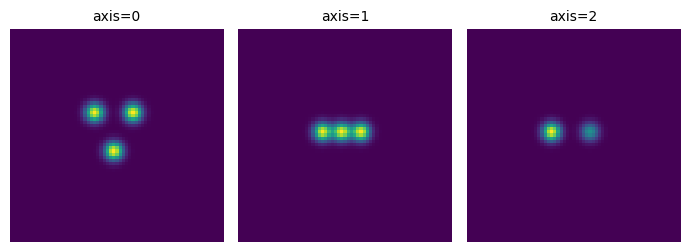

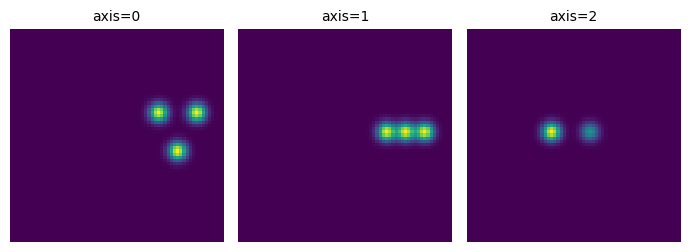

In [3]:
### generate initial volume
N = 37
sigma = 2
f = utils.generate_3d_triangle_gaussian_shape(N, sigma)
# f = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)
f = signals.Signal(f, d=3).preprocess_signals()

### zero pad to allow for shifting
w = 15
f = np.pad(f[0], pad_width=((w, w), (w, w), (w, w)))
print(f.shape)

plots.orthogonal_2D_projection_plot(f)

f_shift = transforms.translate_3d(f, 0, 0, 20)
plots.orthogonal_2D_projection_plot(f_shift)

In [4]:
# plt.imshow(f.sum(axis=0))
# plt.show()
# plt.imshow(f_shift.sum(axis=0))
# plt.show()
# plt.imshow(f.sum(axis=0) - f_shift.sum(axis=0))
# plt.show()

In [5]:
n_shifts = 20
shifts = np.arange(n_shifts+1)

thetas = np.linspace(0, np.pi, f.shape[0], endpoint=True)

dists_l2 = np.zeros(n_shifts+1)
dists_sw = np.zeros(n_shifts+1)
dists_rfsw = np.zeros(n_shifts+1)

t = time.time()
U = transforms.Transform(f, d=3, apply_ramp=False).inverse_cdf_transform()[0]
print('transform time: ', time.time() - t)

t = time.time()
Up, Un = transforms.Transform(f, d=3, apply_ramp=True).signed_inverse_cdf_transform()
print('signed transform time: ', time.time() - t)

for idx, s in enumerate(shifts):
    
    f_shift = transforms.translate_3d(f, 0, 0, s)
    
    V = transforms.Transform(f_shift, d=3, apply_ramp=False).inverse_cdf_transform()[0]
    Vp, Vn = transforms.Transform(f_shift, d=3, apply_ramp=True).signed_inverse_cdf_transform()
    
    ### EV: need to add the normalizing constants and vol element to sliced distances here?
    dists_sw[idx] = distances.sliced_distance_3d(U, V, thetas)
    dists_rfsw[idx] = distances.signed_sliced_distance_3d(Up[0], Vp[0], Un[0], Vn[0], thetas)
    dists_l2[idx] = np.linalg.norm(f - f_shift)**2

transform time:  0.2667984962463379
signed transform time:  0.2758500576019287


In [6]:
dists_l2_normalized = np.sqrt(dists_l2 / np.amax(dists_l2))
dists_sw_normalized = np.sqrt(dists_sw / np.amax(dists_sw))
dists_rfsw_normalized = np.sqrt(dists_rfsw / np.amax(dists_rfsw))

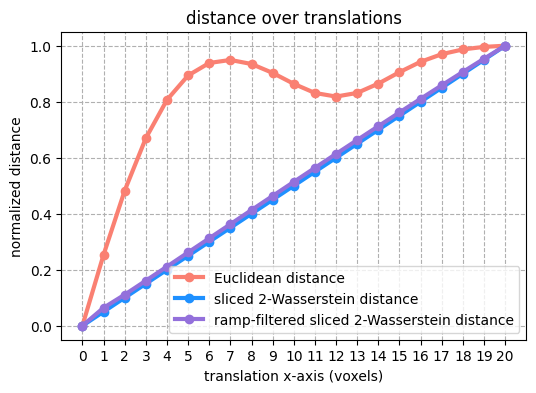

In [7]:
plt.figure(figsize=(6,4))

plt.plot(shifts, dists_l2_normalized, label='Euclidean distance', color='salmon', linewidth=3, linestyle='-', marker='o')
plt.plot(shifts, dists_sw_normalized, label='sliced 2-Wasserstein distance', color='dodgerblue', linewidth=3, linestyle='-', marker='o')
plt.plot(shifts, dists_rfsw_normalized, label='ramp-filtered sliced 2-Wasserstein distance', color='mediumpurple', linewidth=3, linestyle='-', marker='o')

plt.xticks(shifts)
plt.grid(which='major', linestyle='--')
plt.xlabel('translation x-axis (voxels)')
plt.ylabel('normalized distance')
plt.title('distance over translations')
plt.legend()
plt.show()

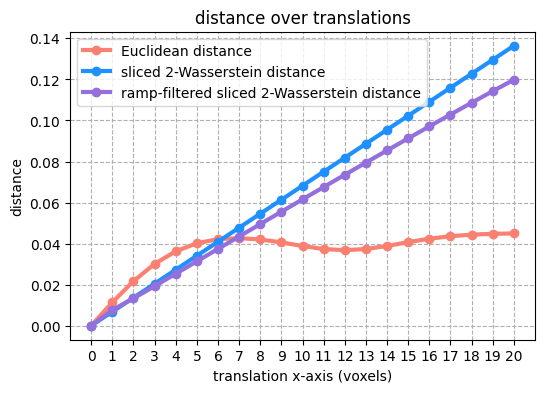

In [8]:
plt.figure(figsize=(6,4))

plt.plot(shifts, np.sqrt(dists_l2), label='Euclidean distance', color='salmon', linewidth=3, linestyle='-', marker='o')
plt.plot(shifts, np.sqrt(dists_sw), label='sliced 2-Wasserstein distance', color='dodgerblue', linewidth=3, linestyle='-', marker='o')
plt.plot(shifts, np.sqrt(dists_rfsw), label='ramp-filtered sliced 2-Wasserstein distance', color='mediumpurple', linewidth=3, linestyle='-', marker='o')

plt.xticks(shifts)
plt.grid(which='major', linestyle='--')
plt.xlabel('translation x-axis (voxels)')
plt.ylabel('distance')
plt.title('distance over translations')
plt.legend()
plt.show()

In [9]:
### timing test

N = 67
thetas = np.linspace(0, np.pi, N, endpoint=True)
f = utils.generate_3d_triangle_gaussian_shape(N, sigma)
f = signals.Signal(f, d=3).preprocess_signals()

for n_trial in range(5):
    t = time.time()
    U = transforms.Transform(f, d=3, apply_ramp=False).inverse_cdf_transform()[0]
    V = transforms.Transform(f, d=3, apply_ramp=False).inverse_cdf_transform()[0]
    d = distances.sliced_distance_3d(U, V, thetas)
    print(time.time() - t)

0.5241420269012451
0.5244066715240479
0.5234158039093018
0.5228390693664551
0.5230932235717773
